# Task 0: Research about BigBird Model

## Introduction

BigBird is a Transformer model designed to process long sequences more efficiently than standard Transformer models such as BERT.

One of the main problems with standard Transformers is the self-attention mechanism. In standard self-attention, every token attends to every other token. Because of this, the computational and memory cost grows quadratically with the sequence length.

BigBird addresses this problem by using a sparse attention mechanism instead of full attention. It combines local attention, random attention, and global attention to reduce the number of attention connections while still allowing information to move between different parts of a long sequence.

In this research, we will explain the motivation behind BigBird, its architecture, sparse attention mechanism, block-sparse patterns, computational complexity, and its differences from BERT and Longformer. We will also discuss its applications, advantages, limitations, and performance characteristics.

## 1. What is BigBird?

BigBird is a Transformer-based model introduced to handle much longer sequences than traditional Transformer models.

It keeps the main idea of the Transformer architecture, but changes how the self-attention mechanism works.

Instead of allowing every token to attend to every other token, BigBird uses a sparse attention pattern. This means that each token attends to only a selected number of other tokens.

BigBird uses three main types of attention:

- **Local attention:** connects nearby tokens.
- **Random attention:** creates connections between distant parts of the sequence.
- **Global attention:** allows some important tokens to communicate with the whole sequence.

By combining these three types, BigBird can process long documents with much lower attention complexity than standard full self-attention.

## 2. Motivation: Why Do We Need BigBird?

Many real-world NLP tasks contain long documents.

For example:

- Research papers
- Books
- Legal documents
- Medical documents
- Long reports
- Long question-answering tasks

These documents can contain thousands of tokens.

Using standard self-attention on such long sequences can become expensive because every token needs to interact with every other token.

For example, if a sequence contains 1,000 tokens, full attention creates:

$$
1000 \times 1000 = 1{,}000{,}000
$$

attention relationships.

If the sequence becomes 4,000 tokens long:

$$
4000 \times 4000 = 16{,}000{,}000
$$

relationships are required.

Therefore, we need a way to process long sequences without calculating all possible token-to-token relationships.

This is the main motivation behind BigBird.

## 3. The Problem with Standard Self-Attention

Standard Transformer models such as BERT use full self-attention.

This means that every token can attend to every other token in the input sequence.

For a sequence with length $n$, the attention matrix has the following size:

$$
n \times n
$$

Therefore, the computational and memory complexity of the attention mechanism is approximately:

$$
\boxed{O(n^2)}
$$

This is called quadratic complexity.

The problem becomes more serious as the sequence length increases.

For example:

$$
512^2 = 262{,}144
$$

while:

$$
4096^2 = 16{,}777{,}216
$$

So, increasing the sequence length by 8 times increases the number of attention relationships by:

$$
8^2 = 64
$$

This makes full self-attention expensive for long documents.

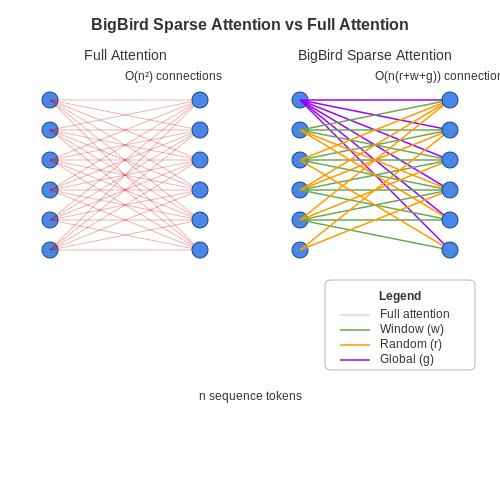

## 4. BigBird Architecture

BigBird is based on the Transformer encoder architecture, so its general structure is similar to models such as BERT.

The main difference is the attention mechanism.

In BERT, the self-attention layer uses full attention, where every token can attend to every other token.

BigBird replaces this full attention with a block-sparse attention mechanism that combines local, random, and global attention.

A simplified view of the architecture is:

```
Input Tokens
      ↓
Token Embeddings
      ↓
Transformer Encoder
      ↓
Sparse Attention
(Local + Random + Global)
      ↓
Feed Forward Network
      ↓
Output
```

## 5. BigBird's Sparse Attention Mechanism

BigBird calculates attention only between selected tokens instead of every possible pair.

### 1. Local Attention
A token attends to nearby tokens, helping the model understand relationships between nearby words.

### 2. Random Attention
A token attends to a few randomly selected tokens across the sequence. This connects distant parts of a document.

### 3. Global Attention
Selected important tokens, such as `[CLS]`, can attend to the whole sequence, and other tokens can attend to them.

Together, these patterns help BigBird capture both local and long-range information.

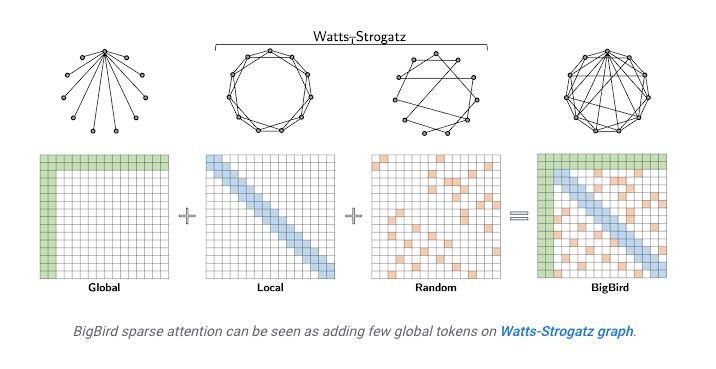

### How to read the figure

The figure shows each attention type as a matrix, and how they are added together to get BigBird:

- **Global (green):** the first rows and columns. These tokens connect with the whole sequence.
- **Local (blue):** the diagonal band. Each token connects with its nearby tokens.
- **Random (orange):** scattered cells. These connect distant parts of the sequence.
- **BigBird:** the three patterns combined.

The important idea is that BigBird does not remove long-range communication completely. Instead, it uses a small number of carefully selected connections to make it more efficient.

## 6. Block-Sparse Attention

BigBird uses block-sparse attention to organize the sparse connections.

Instead of treating the whole sequence as one large attention matrix, the sequence is divided into smaller blocks.

For example:

Block 1 | Block 2 | Block 3 | Block 4 | Block 5 | Block 6

Each block contains several tokens.

BigBird does not calculate attention between every possible pair of blocks.

Instead, it creates attention connections only between selected blocks.

For example:

```
        B1  B2  B3  B4  B5  B6
B1      G   G   G   G   G   G
B2      G   L   L   .   .   R
B3      G   L   L   L   .   .
B4      G   .   L   L   L   .
B5      G   R   .   L   L   L
B6      G   .   .   .   L   L
```

Where:

- G = global attention (B1 is a global block)
- L = local attention
- R = random attention
- . = no direct attention

This produces a sparse attention matrix and reduces the amount of computation compared with full attention.

### Why Use Blocks?

Using blocks makes the sparse attention pattern easier to organize and compute.

Instead of thinking about thousands of individual tokens, we group them into blocks and choose which blocks attend to each other.

Working with blocks is also more efficient on GPUs and TPUs than working with scattered individual tokens.

## 7. Why Are Random and Global Attention Important?

Local attention is useful for understanding nearby information, but it has a limitation.

If a token can only attend to nearby tokens, it may be difficult for information to move between very distant parts of a long document.

For example, an important piece of information may appear at the beginning of a document, while another related piece of information appears near the end.

BigBird addresses this problem using random and global attention.

### Random Attention

Random connections work like shortcuts between distant blocks, so information can reach far parts of the sequence in only a few steps.

### Global Attention

Global tokens work like hubs. They can attend to the whole sequence, and all other tokens can attend to them, so any two tokens can exchange information through a global token.

## 9. Computational Complexity

The main advantage of BigBird comes from reducing the number of attention connections.

In standard self-attention, every token attends to every other token.

For a sequence of length $n$, this gives:

$$
n \times n
$$

attention connections.

Therefore, the complexity is:

$$
\boxed{O(n^2)}
$$

This is the complexity used by standard full attention in models such as BERT.

BigBird only allows each token or block to attend to a limited number of other tokens or blocks.

If the number of local, random, and global connections is kept fixed, the number of attention calculations grows approximately linearly with the sequence length.

Therefore, BigBird has approximately:

$$
\boxed{O(n)}
$$

attention complexity.

This is a major improvement for long sequences because the cost does not grow quadratically with the sequence length.

### A Simple Complexity Example

Suppose we have a sequence with:

$$
n = 4096
$$

For full self-attention:

$$
n^2 = 4096^2 = 16{,}777{,}216
$$

So the model needs to consider more than 16 million possible attention relationships.

With BigBird, each token attends to a fixed number of tokens. For example, if each token attends to about 512 tokens (local + random + global together), the cost is about:

$$
4096 \times 512 = 2{,}097{,}152
$$

This is 8 times smaller than full attention.

If the sequence becomes 8 times longer, the cost of full attention grows by $8^2 = 64$ times, while the cost of BigBird grows by only 8 times.

The exact number of operations depends on the configuration, but this example shows the main difference between quadratic and linear growth.

### Interpretation

The graph compares quadratic and linear growth. BERT's full attention grows much faster, while BigBird's cost grows approximately linearly when the number of connections stays fixed.

The graph ignores constant factors and shows only how the cost grows with sequence length.

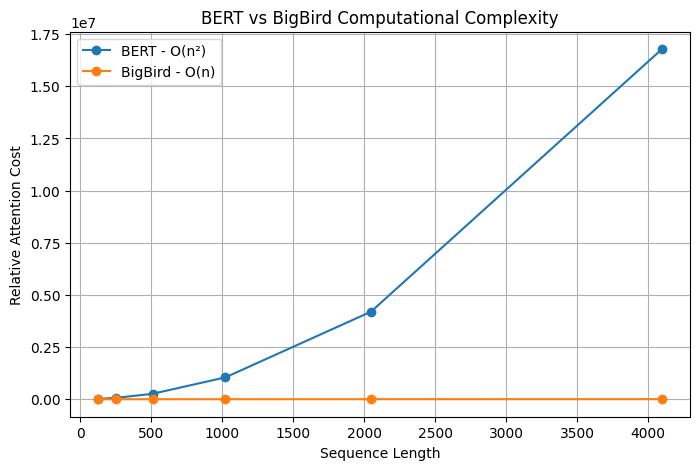

## 10. BigBird vs BERT vs Longformer

BERT, Longformer, and BigBird are all Transformer-based models, but they use different attention mechanisms.

### BERT

BERT uses full self-attention.

Every token can attend to every other token in the sequence.

Therefore, its attention complexity is:

$$
O(n^2)
$$

This works well for shorter sequences, but it becomes expensive when the input is very long.

### Longformer

Longformer uses sparse attention based mainly on local sliding-window attention.

Each token attends to a limited number of nearby tokens.

It also supports global attention for selected tokens.

Its attention complexity is approximately:

$$
O(nw)
$$

where $n$ is the sequence length and $w$ is the local attention window.

If the window size is fixed, the complexity is approximately linear with respect to the sequence length.

### BigBird

BigBird uses block-sparse attention and combines:

- Local attention
- Random attention
- Global attention

Its complexity can be written approximately as:

$$
O(n(w+r+g))
$$

where:

- $w$ = local attention connections
- $r$ = random attention connections
- $g$ = global attention connections

If these values are kept fixed, the complexity becomes approximately:

$$
O(n)
$$

Therefore, both Longformer and BigBird are designed to make Transformer models more efficient for long sequences.

## 11. Comparison Table

| Feature | BERT | Longformer | BigBird |
|---|---|---|---|
| Attention Type | Full | Sparse | Block-Sparse |
| Local Attention | No (full attention) | Yes | Yes |
| Random Attention | No | No | Yes |
| Global Attention | No | Yes | Yes |
| Main Attention Pattern | Dense | Sliding Window + Global | Local + Random + Global |
| Complexity | $O(n^2)$ | $O(nw)$ | Approximately $O(n)$ |
| Long Sequence Support | Limited | Good | Good |
| Main Goal | General NLP | Efficient long-context processing | Efficient long-context processing |

Here, $n$ is the sequence length and $w$ is the local attention window used by Longformer.

For BigBird, the linear complexity assumes that the number of local, random, and global connections is kept fixed.

### Main Difference

The main difference between the three models is how they decide which tokens should attend to each other.

BERT uses:

$$
\text{Every token} \rightarrow \text{Every token}
$$

Longformer mainly uses:

$$
\text{Local tokens} + \text{Global tokens}
$$

BigBird uses:

$$
\text{Local tokens} + \text{Random tokens} + \text{Global tokens}
$$

The random attention mechanism is one of the main differences between BigBird and Longformer.

It allows BigBird to create additional long-range connections between different parts of the document.

## 12. Suitable Applications for BigBird

BigBird is most useful when the input contains a large amount of text or a long sequence.

Some suitable applications include:

### 1. Long Document Question Answering

A question may require information from different parts of a long document.

BigBird can process a larger context and help connect information from distant sections.

### 2. Document Summarization

Research papers, reports, books, and other long documents can contain thousands of tokens.

BigBird can process longer inputs than standard full-attention models.

### 3. Document Classification

BigBird can be useful for classifying long documents, such as:

- Legal documents
- Medical documents
- Research papers
- News articles
- Reports

### 4. Genomic Sequences

BigBird has also been explored for processing long genomic sequences.

### 5. Other Long-Context NLP Tasks

In general, BigBird is useful when understanding information from different parts of a long input is important.

## 13. Advantages of BigBird

### 1. Handles Long Sequences
It can process longer inputs and reduce information loss caused by truncating documents.

### 2. Lower Attention Complexity
With a fixed number of connections, attention complexity drops from $O(n^2)$ to approximately $O(n)$.

### 3. Captures Different Relationships
Local attention captures nearby information, random attention connects distant parts, and global attention helps information move across the sequence.

### 4. Supports Different Tasks
It can be used for question answering, summarization, document classification, and genomic sequence analysis.

## 14. Limitations of BigBird

Although BigBird improves the efficiency of Transformer models, it also has some limitations.

### 1. Sparse Attention is an Approximation

BigBird does not allow every token to directly attend to every other token.

Some relationships must be learned through indirect connections.

### 2. More Complex Architecture

The attention mechanism is more complicated than standard full attention.

The model needs to manage local, random, and global connections.

### 3. Configuration is Important

The performance can depend on parameters such as:

- Block size
- Number of random connections
- Number of global tokens
- Sequence length

Choosing these parameters correctly is important.

### 4. Not Always Better for Short Sequences

For short inputs, the advantages of sparse attention may be smaller.

The additional sparse-attention structure may not provide a large benefit compared with standard attention.

### 5. Theoretical Complexity is Not the Same as Actual Speed

Although BigBird has lower theoretical complexity, the actual runtime also depends on the implementation, hardware, and available optimized libraries.

Therefore, lower complexity does not always mean that BigBird will be faster for every input size.

## 15. Performance Characteristics

BigBird is designed to make processing long sequences more efficient by reducing the number of attention connections.

Its main performance characteristics are:

* **Lower attention complexity:** BigBird uses sparse attention to reduce the computational cost compared with standard full attention.
* **Support for longer sequences:** It can process longer inputs, such as 4096 tokens, compared with the 512-token limit commonly used in standard BERT configurations.
* **Long-context understanding:** Its local, random, and global attention mechanisms help the model capture both nearby information and relationships between distant parts of a sequence.
* **Task-dependent performance:** Its effectiveness depends on the task, sequence length, and attention configuration.

For short sequences, the benefits of sparse attention may be less significant. For long sequences, reducing the number of attention connections can provide greater computational savings.


## 16. Conclusion

BigBird processes long sequences more efficiently than standard full-attention Transformers.

BERT uses full self-attention with $O(n^2)$ complexity. BigBird reduces the number of connections with block-sparse attention, combining local, random, and global patterns to achieve approximately linear attention complexity when the connection settings stay fixed.

Compared with BERT, BigBird is better suited to long documents. Compared with Longformer, it adds random attention to local and global attention.

Overall, BigBird is useful for long-context tasks where reducing attention cost is important.